# Урок 2 — Одна гауссиана на прямой: разбираем колокол

[К программе и запуску примеров](../../README_ru.md) · [Предыдущий урок](lesson-01.ipynb) · [English version](../en/lesson-02.ipynb)

**Результат урока:** ты сможешь построить колокол, передвинуть его, изменить ширину и вручную вычислить значение в любой выбранной точке. Каждая операция в формуле будет иметь понятный смысл.

Нужны обычные арифметические действия и умение запустить ячейку Python. Производных, матриц и теории вероятностей здесь нет. Мы занимаемся только **однимерной** гауссианой: одна входная координата → одно число на выходе.

В первом уроке гауссианы были мягкими пятнами, из которых собирается изображение. Здесь рассматриваем профиль одного такого пятна вдоль линии: в середине сильнее, дальше слабее. Это учебная весовая функция. До расчёта цвета пикселя и перекрытий ещё дойдём.

## 1. Сначала посмотрим и потрогаем

Запускай ячейки сверху вниз. Первая находит папку курса и подключает готовые средства визуализации. Их устройство сейчас разбирать не нужно: ниже вычислим саму гауссиану обычными арифметическими действиями.

Вторая ячейка показывает исходный график и интерактивную лабораторию. В статической версии урока график остаётся виден; для ползунков открой этот notebook в Jupyter по инструкции в README.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

LANG = "ru"

course_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "course_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook from the course repository.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from IPython.display import display
from course_demos import (
    gaussian_lab,
    gaussian_figure,
    construction_figure,
    width_figure,
)

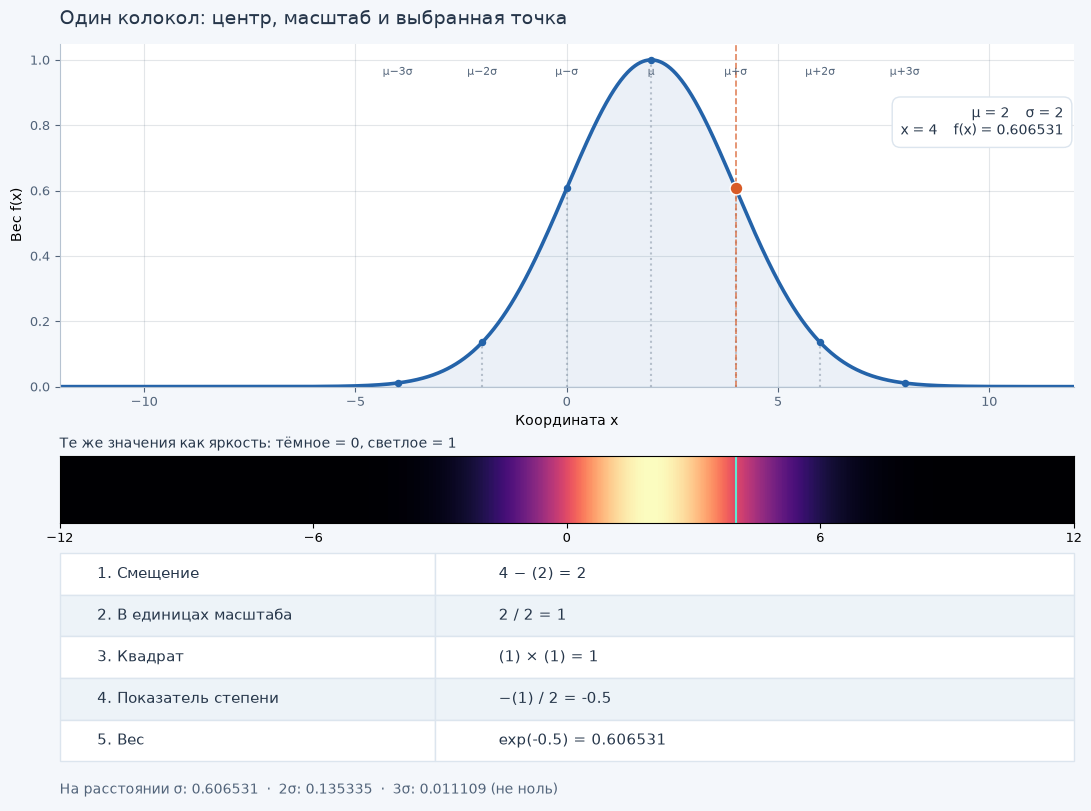

In [2]:
display(gaussian_figure(mu=2, sigma=2, x=4, language=LANG))
display(gaussian_lab(language=LANG))

Пока **не пытайся читать формулу**. Сделай три опыта:

1. Передвинь центр с 2 на −2. Колокол переедет, но его форма и высота сохранятся.
2. Верни центр в 2 и уменьши ширину с 2 до 1. Колокол станет уже, а высота вершины останется равной 1.
3. Верни ширину в 2 и двигай выбранную точку вдоль графика. Меняется точка измерения и её значение; сам колокол остаётся прежним.

Горизонтальная ось — координата на линии. Вертикальная ось — **вес**: насколько сильно гауссиана влияет в этом месте. Это не высота реального объекта. Светлая полоса под графиком кодирует те же значения яркостью: больше вес → светлее.

Оси графика остаются на месте. Поэтому движение центра не маскируется движением «камеры». Во всех следующих расчётах используем одни параметры: **центр 2, ширина 2**. Начальная выбранная точка — **4**.

## 2. Как прочитать одну точку графика

Представь линейку. Мы выбрали отметку 4 и хотим узнать вес в этом месте.

| Запись | Как читать | Роль в примере |
|---|---|---|
| $x$ | «икс» | Координата, которую проверяем: 4 |
| $\mu$ | «мю» | Центр колокола: 2 |
| $\sigma$ | «сигма» | Масштаб ширины: 2; обязательно больше нуля |
| $f(x)$ | «эф от икс» | Результат вычисления веса в координате $x$ |

Скобки в $f(x)$ обозначают вход функции. Это **не** умножение буквы $f$ на число $x$. Слово «функция» здесь означает правило: получил координату — выполнил действия — вернул число.

У нашего колокола $f(2)=1$: в центре вес максимален. Запись $f(4)$ означает «вычисли вес в точке 4». Дальше получим приблизительно 0.606531.

Параметры $\mu$ и $\sigma$ определяют весь колокол. Координата $x$ выбирает место, где мы этот уже заданный колокол измеряем.

## 3. Шаг первый: отсчитываем от центра

Координата сама по себе не говорит, далеко ли мы от колокола. Точка 100 может быть прямо в центре, если центр тоже 100.

Поэтому сначала вычитаем центр:

$$
d=x-\mu.
$$

Буква $d$ — короткое имя промежуточного результата: **смещения от центра**. При $x=4$ и $\mu=2$:

$$
d=4-2=2.
$$

Мы на две единицы правее центра. Теперь возьмём $x=0$:

$$
d=0-2=-2.
$$

Мы на две единицы левее центра. Знак хранит сторону, а величина 2 — удалённость. В самом центре получаем $d=2-2=0$.

Мы хотим одинаковое влияние на одинаковом расстоянии слева и справа. Пока результаты $2$ и $-2$ различаются. Через два шага устраним эту разницу.

## 4. Шаг второй: измеряем смещение в единицах ширины

Удалённость 2 — много или мало? Для очень узкого пятна это далеко. Для широкого — близко. Нужно сравнить смещение с шириной:

$$
u=\frac{d}{\sigma}.
$$

Дробная черта означает деление. Новая буква $u$ обозначает **смещение, измеренное в единицах ширины**. В примере:

$$
u=\frac{2}{2}=1.
$$

То есть точка находится на одну ширину правее центра. Слева получаем $(-2)/2=-1$.

Если оставить точку и центр прежними, но сделать $\sigma=1$, то $u=2/1=2$: та же точка теперь находится на две ширины от центра. Если сделать $\sigma=4$, то $u=2/4=0.5$: всего на половину ширины.

Величины $x,\mu,\sigma$ используют одинаковые единицы. Если координаты в сантиметрах, то и ширина в сантиметрах. В отношении «2 см / 2 см» единицы сокращаются, остаётся число 1. Такое число называют **безразмерным**. Это важно: дальнейшая формула зависит от относительного положения, а не от выбора сантиметров или метров.

$\sigma$ — масштаб ширины, а не граница пятна и не его полная ширина. В этом уроке у колокола вообще нет резкого края.

## 5. Шаг третий: делаем левую и правую стороны одинаковыми

Возведём относительное смещение в квадрат:

$$
q=u^2=u\cdot u.
$$

Маленькая двойка сверху означает «умножь число само на себя». Точка посередине — знак умножения.

Справа от центра:

$$
q=1^2=1\cdot1=1.
$$

Слева от центра:

$$
q=(-1)^2=(-1)\cdot(-1)=1.
$$

Произведение двух отрицательных чисел положительно. Поэтому обе стороны дают один результат. В центре $q=0^2=0$. На расстоянии двух ширин $q=2^2=4$, трёх ширин — $q=3^2=9$.

Квадрат выполняет две работы: убирает различие сторон и увеличивает результат быстрее при удалении от центра. Но пока это «мера удалённости»: в центре ноль, дальше больше. Нам нужен **вес** с обратным поведением: в центре максимум, дальше меньше.

Почему квадрат, а не другое действие? Это выбор формы гауссианы. Можно построить другие симметричные пятна, например используя модуль — величину без знака. Они дадут другие профили. Наша задача — понять конкретную конструкцию, а не доказать, что любая мягкая форма обязана быть гауссианой.

## 6. Шаг четвёртый: готовим число для убывания

Теперь делим квадрат на 2 и меняем знак:

$$
t=-\frac{q}{2}.
$$

Буква $t$ здесь — промежуточное число, **не время**. Сначала деление, затем минус:

- в центре: $q=0$, поэтому $t=-0/2=0$;
- на одной ширине: $q=1$, поэтому $t=-1/2=-0.5$;
- на двух ширинах: $q=4$, поэтому $t=-4/2=-2$;
- на трёх ширинах: $q=9$, поэтому $t=-9/2=-4.5$.

Теперь при удалении от центра число становится всё более отрицательным. Следующая операция превратит это в всё меньший **положительный** вес.

Делитель 2 регулирует скорость убывания. Он входит в принятое определение масштаба гауссианы. Удалить его можно, но тогда при том же числовом $\sigma$ получится более узкий колокол. Ниже сравним это отдельно. Наличие именно двойки не требуется для существования любой колоколообразной кривой.

## 7. Последний шаг: что такое exp и число e

Мы дошли до $t=-0.5$, но это ещё не вес. Нам нужна операция, у которой:

- вход 0 даёт выход 1;
- отрицательный вход даёт положительное число меньше 1;
- более отрицательный вход даёт меньший выход.

Так работает экспонента:

$$
\exp(t)=e^t.
$$

Слева «exp» — имя функции, $t$ в скобках — её вход. Справа та же операция записана как степень. $e$ — постоянное число, приблизительно **2.71828**; $t$ — показатель степени. «Приблизительно» означает, что здесь показаны только первые цифры.

Чтобы запись не оставалась магией, сначала разберём степени на обычном числе 2.

### Положительная, нулевая и отрицательная степень

У положительной целой степени смысл прямой:

$$
2^1=2,\qquad 2^2=2\cdot2=4,\qquad 2^3=2\cdot2\cdot2=8.
$$

Переход от степени 3 к степени 2 — деление на 2: $8/2=4$. Ещё шаг вниз: $4/2=2$. Продолжим то же правило:

| Показатель | Действие | Значение |
|---|---|---:|
| 1 | Начальное число | 2 |
| 0 | $2/2$ | 1 |
| −1 | $1/2$ | 0.5 |
| −2 | $0.5/2$ | 0.25 |

Поэтому $2^0=1$, а $2^{-2}=1/(2\cdot2)=1/4$.

То же правило работает для любого положительного основания, в том числе для $e$:

$$
e^0=1,\qquad e^{-1}=\frac{1}{e},\qquad e^{-2}=\frac{1}{e^2}.
$$

**Отрицательная степень не делает ответ отрицательным.** Она означает переход к обратному числу: единица, делённая на положительную степень.

### Половинная степень

Что означает степень 0.5? Это половина единицы: $0.5=1/2$. Для положительного числа степень $1/2$ означает **квадратный корень**.

Корень из числа — такое неотрицательное число, которое при умножении само на себя даёт исходное. Например, $\sqrt{9}=3$, потому что $3\cdot3=9$. Знак $\sqrt{\phantom{9}}$ читается «квадратный корень».

Две одинаковые половины показателя вместе дают показатель 1. Поэтому $e^{1/2}\cdot e^{1/2}=e^1=e$, то есть $e^{1/2}=\sqrt{e}$. Теперь применим правило отрицательной степени:

$$
e^{-0.5}=\frac{1}{e^{0.5}}=\frac{1}{\sqrt{e}}.
$$

Посчитаем приблизительно:

$$
e\approx2.71828,\qquad
\sqrt{e}\approx1.64872,\qquad
\frac{1}{1.64872}\approx0.60653.
$$

Знак $\approx$ читается «приблизительно равно». В итоговом расчёте Python использует более точное значение $e$, поэтому мы округляем только для показа.

Другие дробные показатели продолжают ту же идею. Например, степень $1/4$ — число, которое нужно перемножить само с собой четыре раза, чтобы получить основание. Для произвольного вещественного показателя экспонента продолжает эти значения в непрерывную кривую. Вычислять такую степень вручную каждый раз не требуется: её считает `math.exp`.

### Откуда взялось именно число e

Вот арифметическая конструкция, позволяющая приблизиться к $e$.

Начни с 1. Если один раз увеличить значение на 100%, получишь $1\cdot(1+1)=2$. Теперь раздели увеличение на два последовательных шага по 50% **от текущего значения**:

$$
1\cdot(1+1/2)\cdot(1+1/2)=1\cdot1.5\cdot1.5=2.25.
$$

Результат больше 2, потому что второй раз увеличиваем уже 1.5, а не начальную единицу.

Если разделить процесс на $n$ одинаковых шагов, каждый умножает текущий результат на $1+1/n$. Буква $n$ — число шагов; это положительное целое число. После $n$ умножений получаем:

$$
a_n=\left(1+\frac{1}{n}\right)^n.
$$

Запись $a_n$ — имя результата для выбранного числа шагов, индекс снизу напоминает, какое $n$ мы взяли. Сначала делим 1 на $n$, прибавляем 1, затем умножаем полученное число само на себя $n$ раз.

При всё большем $n$ результаты приближаются к одному числу. Этим предельным числом и определяется $e$. Слово «предельное» здесь означает значение, к которому приближается последовательность при неограниченном увеличении числа шагов. Конечное $n$ даёт приближение, а не точное равенство.

Следующая ячейка показывает это численно. `**` в Python — возведение в степень. `.8f` задаёт восемь цифр после десятичной точки только при печати.

In [3]:
import math

for n in [1, 2, 10, 100, 1000, 10000]:
    approximation = (1 + 1 / n) ** n
    print(f"n = {n:5d} -> {approximation:.8f}")

print(f"math.e     -> {math.e:.8f}")

n =     1 -> 2.00000000
n =     2 -> 2.25000000
n =    10 -> 2.59374246
n =   100 -> 2.70481383
n =  1000 -> 2.71692393
n = 10000 -> 2.71814593
math.e     -> 2.71828183


Так мы получили представление о самом числе $e$, не вводя производные. Выбор экспоненты с этим основанием даёт привычную запись гауссианы. Наблюдение «пятно мягкое» само по себе не выводит число $e$, квадрат и коэффициент $1/2$: вместе это выбранная математическая модель.

Проверим нужные нам значения. В записи `math.exp(t)` модуль `math` содержит математические функции, а `exp` вычисляет $e^t$. В цикле `t` по очереди получает четыре указанных значения.

In [4]:
for t in [0, -0.5, -2, -4.5]:
    weight = math.exp(t)
    print(f"exp({t:4.1f}) = {weight:.6f}")

exp( 0.0) = 1.000000
exp(-0.5) = 0.606531
exp(-2.0) = 0.135335
exp(-4.5) = 0.011109


Обрати внимание: число $-4.5$ гораздо меньше нуля, но $\exp(-4.5)$ всё ещё **положительно** — примерно 0.011109. Это 1.1109% от вершины, потому что $0.011109\cdot100=1.1109$.

Процент означает «доля от ста». Здесь он сравнивает значение с вершиной 1. Это не вероятность попасть в точку и не доля площади под кривой.

## 8. Собираем все действия в одну формулу

Наш рецепт:

$$
d=x-\mu,\qquad
u=\frac{d}{\sigma},\qquad
q=u^2,\qquad
t=-\frac{q}{2},\qquad
f(x)=\exp(t).
$$

Каждая буква после знака равенства использует результат предыдущего шага. Если последовательно подставить промежуточные выражения, получится:

$$
f(x)=\exp\left(-\frac{1}{2}
\left(\frac{x-\mu}{\sigma}\right)^2\right).
$$

Здесь умножение на $1/2$ — то же самое, что деление на 2. Квадрат дроби можно развернуть:

$$
\left(\frac{x-\mu}{\sigma}\right)^2
=
\frac{x-\mu}{\sigma}\cdot\frac{x-\mu}{\sigma}
=
\frac{(x-\mu)(x-\mu)}{\sigma\cdot\sigma}
=
\frac{(x-\mu)^2}{\sigma^2}.
$$

Мы перемножили числители друг с другом, знаменатели — друг с другом. Отсюда компактная запись:

$$
\boxed{f(x)=\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)}.
$$

Квадрат ширины в знаменателе не появился из ниоткуда: он получился, когда мы возвели **всю относительную удалённость** в квадрат. Скобки вокруг $x-\mu$ важны: сначала вычитаем центр, затем возводим результат в квадрат.

На рисунке ниже можно проследить преобразование всей линии, а отмеченная точка показывает наши промежуточные числа.

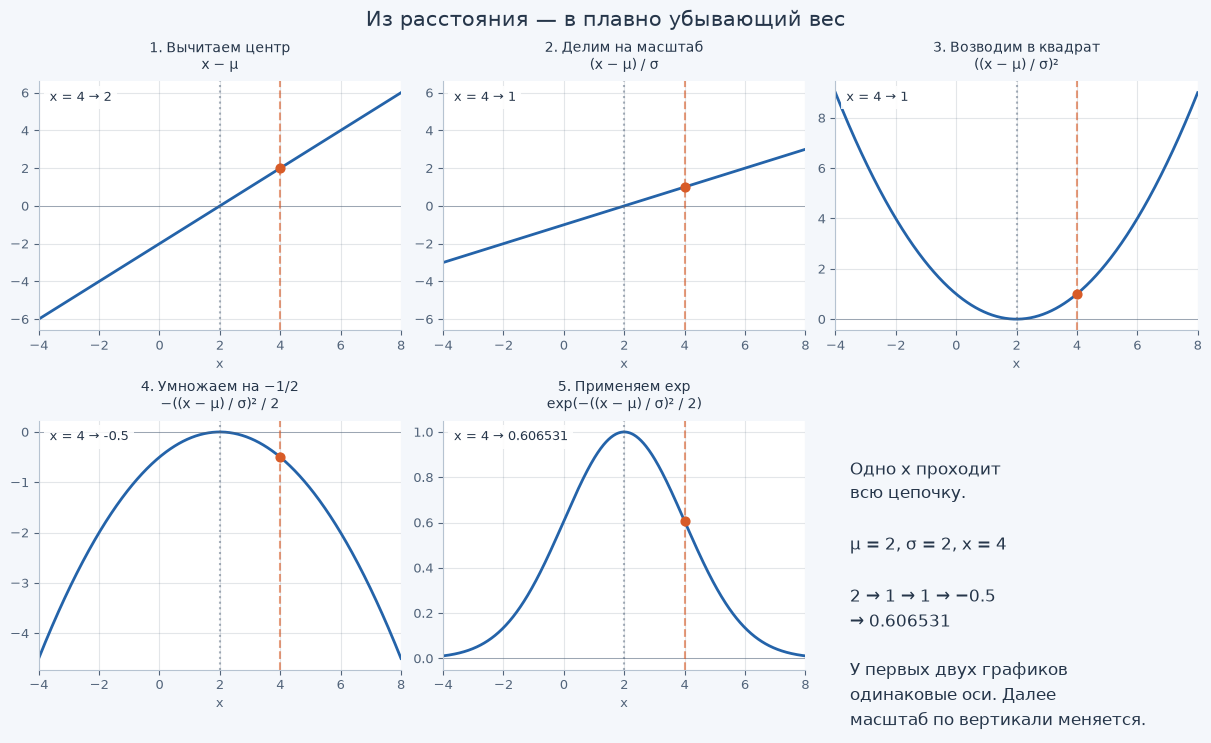

In [5]:
display(construction_figure(language=LANG))

## 9. Полный расчёт: точка 4, центр 2, ширина 2

Пройдём путь ещё раз, уже без новых понятий.

| Шаг | Вычисление | Смысл |
|---|---|---|
| Смещение | $4-2=2$ | Две единицы правее центра |
| Деление на ширину | $2/2=1$ | Одна ширина от центра |
| Квадрат | $1\cdot1=1$ | Одинаковый результат для обеих сторон |
| Деление на 2 и минус | $-1/2=-0.5$ | Показатель для убывающего веса |
| Экспонента | $e^{-0.5}\approx0.606531$ | Вес в выбранной точке |

Итак, **$f(4)\approx0.606531$**. На графике это высота точки над отметкой 4. На светлой полосе — соответствующая ей яркость.

Теперь тот же расчёт в Python. Имена переменных повторяют этапы: `offset` — смещение, `relative` — относительное смещение, `squared` — его квадрат, `exponent` — показатель степени, `weight` — итоговый вес. Знак `=` в коде сохраняет результат справа в переменную слева.

In [6]:
x = 4.0
mu = 2.0
sigma = 2.0

offset = x - mu
relative = offset / sigma
squared = relative * relative
exponent = -squared / 2
weight = math.exp(exponent)

print(f"x - mu                 = {offset:.6f}")
print(f"(x - mu) / sigma       = {relative:.6f}")
print(f"relative * relative    = {squared:.6f}")
print(f"-squared / 2           = {exponent:.6f}")
print(f"exp(exponent)          = {weight:.6f}")

x - mu                 = 2.000000
(x - mu) / sigma       = 1.000000
relative * relative    = 1.000000
-squared / 2           = -0.500000
exp(exponent)          = 0.606531


### Проверяем другую сторону и вершину

Для $x=0$, $\mu=2$, $\sigma=2$:

$$
d=0-2=-2,\qquad
u=-2/2=-1,\qquad
q=(-1)\cdot(-1)=1,
$$

$$
t=-1/2=-0.5,\qquad
f(0)=e^{-0.5}\approx0.606531.
$$

Получилось столько же, сколько справа. Вот симметрия, показанная числами.

Для $x=2$, то есть прямо в центре:

$$
d=2-2=0,\qquad
u=0/2=0,\qquad
q=0\cdot0=0,
$$

$$
t=-0/2=0,\qquad
f(2)=e^0=1.
$$

Если ширина положительна, в центре всегда повторяется эта цепочка: нулевое смещение → нулевой показатель → вес 1.

Для $x=6$: $d=6-2=4$, $u=4/2=2$, $q=2\cdot2=4$, $t=-4/2=-2$, поэтому $f(6)=e^{-2}\approx0.135335$.

Для $x=8$: $d=8-2=6$, $u=6/2=3$, $q=3\cdot3=9$, $t=-9/2=-4.5$, поэтому $f(8)=e^{-4.5}\approx0.011109$.

Следующая ячейка повторяет те же действия для всех пяти координат. Никакого нового математического приёма здесь нет: цикл просто делает один расчёт несколько раз.

In [7]:
mu = 2.0
sigma = 2.0

print(" x    offset  relative  squared  exponent    weight")
for x in [2.0, 4.0, 0.0, 6.0, 8.0]:
    offset = x - mu
    relative = offset / sigma
    squared = relative * relative
    exponent = -squared / 2
    weight = math.exp(exponent)
    print(
        f"{x:3.0f}  {offset:8.1f}  {relative:8.1f}  "
        f"{squared:7.1f}  {exponent:8.1f}  {weight:10.6f}"
    )

 x    offset  relative  squared  exponent    weight
  2       0.0       0.0      0.0      -0.0    1.000000
  4       2.0       1.0      1.0      -0.5    0.606531
  0      -2.0      -1.0      1.0      -0.5    0.606531
  6       4.0       2.0      4.0      -2.0    0.135335
  8       6.0       3.0      9.0      -4.5    0.011109


## 10. Что именно меняет ширина и зачем в формуле двойка

Сначала удержим $x=4$ и $\mu=2$, а ширину изменим с 2 на 1:

$$
d=4-2=2,\quad
u=2/1=2,\quad
q=2\cdot2=4,\quad
t=-4/2=-2,
$$

$$
f(4)=e^{-2}\approx0.135335.
$$

Раньше было 0.606531. После сужения та же точка оказалась дальше **в единицах ширины**, поэтому её вес уменьшился. Центр при этом всё ещё имеет вес 1.

Теперь вернём $\sigma=2$, но временно удалим делитель 2 из показателя. При $x=4$ относительное смещение равно 1:

- с делителем: показатель $-1/2=-0.5$, вес около 0.606531;
- без делителя: показатель $-1=-1$, вес около 0.367879.

Без делителя вес убывает быстрее. Это другая числовая настройка ширины.

Можно получить тот же более узкий профиль, сохранив привычную формулу, но изменив ширину. Проверим на числах. При старой ширине 2 и удалённом делителе знаменатель равен $2^2=4$. В обычной формуле нужен такой новый положительный масштаб $w$, чтобы:

$$
2w^2=4.
$$

Здесь $w$ — только имя новой ширины. Делим обе стороны на 2: $w^2=2$. Значит $w=\sqrt{2}\approx1.414214$. Это меньше 2.

Поэтому коэффициент $1/2$ — **часть соглашения о масштабе**, а не единственно возможный способ нарисовать колокол. В статистике масштаб $\sigma$ при таком соглашении совпадает со стандартным отклонением соответствующей нормированной гауссианы. Вычислять статистическое отклонение по данным для этого урока не требуется: здесь $\sigma$ задаёт сам пользователь.

На рисунке слева сравниваем разные ширины в одной формуле, справа — одну ширину при наличии и отсутствии делителя 2.

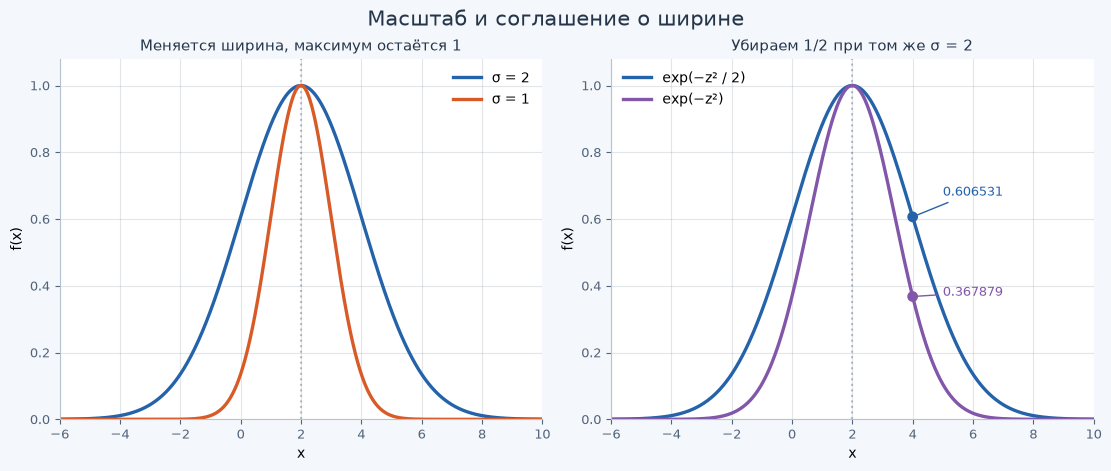

In [8]:
display(width_figure(language=LANG))

## 11. Вес — не вероятность и не непрозрачность

Мы вычисляем **ненормированную гауссиану с вершиной 1**. «Ненормированная» здесь означает, что мы не умножали кривую на дополнительный коэффициент, заставляющий площадь под ней равняться единице.

Представь площадь как количество краски под линией графика. Если растянуть колокол по горизонтали и сохранить высоту, краски станет больше. Нашей задаче это не мешает: функция задаёт пространственный вес, а не распределяет фиксированное количество вероятности.

Поэтому:

- значение 0.606531 означает относительную силу в выбранном месте;
- оно не означает «вероятность 60.6531% оказаться именно здесь»;
- оно не является полной непрозрачностью гауссианы;
- оно ещё не определяет окончательный цвет пикселя.

В дальнейшем к пространственному весу добавятся цвет, параметр непрозрачности и смешивание с другими гауссианами. Здесь оставляем одну задачу: **как плавно уменьшать влияние при удалении от центра**.

Сравнение с фонариком помогает представить плавное пятно, но реальный фонарик не обязан иметь точно гауссов профиль. Аналогия объясняет идею, а численная формула задаёт нашу модель.

## 12. Где формула работает и что происходит на краях

**Ширина строго положительна.** При $\sigma=0$ нужно было бы делить на ноль. Формула в таком виде не определена даже в центре: там возникло бы $0/0$. Значение −2 не используем как ширину: после возведения в квадрат оно дало бы тот же профиль, что и 2, но означать отрицательную длину ширина не должна. Поэтому принимаем однозначное правило $\sigma>0$.

**Точки слева разрешены.** Отрицательная координата $x$ или отрицательный центр $\mu$ совершенно допустимы: это просто отметки слева от нуля на линейке. Не путай знак координаты со знаком ширины.

**Вес не превышает 1.** Квадрат неотрицателен, после деления и минуса показатель не больше нуля. У положительной экспоненты нулевой показатель даёт 1, а отрицательный — меньше 1.

**Граница не обрывается на трёх ширинах.** При удалённости $3\sigma$ вес равен $e^{-4.5}\approx0.011109$, а при $4\sigma$: относительное смещение 4 → квадрат 16 → показатель $-16/2=-8$ → вес $e^{-8}\approx0.000335$.

В точной математике для любой конечной координаты и положительной конечной ширины вес больше нуля. На компьютере очень маленькое значение иногда округляется до нуля из-за ограниченной точности хранения. Это ограничение вычислений, а не обрыв математической кривой.

При рендеринге слабые хвосты иногда отбрасывают ради скорости. Но «после $3\sigma$ всегда можно забыть обо всём» — неверное универсальное правило: значимость вклада зависит и от непрозрачности, и от других элементов, и от точности, которую мы хотим получить.

## 13. Своя функция и эксперименты

Соберём уже знакомые действия в функцию. Она получает `x`, `mu`, `sigma` и возвращает один вес. Проверка `sigma <= 0` останавливает расчёт с понятной ошибкой при недопустимой ширине.

Используем обычные конечные числа; не вводи бесконечность или специальные значения вроде `NaN`. Все пять промежуточных действий остаются отдельными строками, чтобы формулу можно было прочитать сверху вниз.

In [9]:
def gaussian_weight(x, mu, sigma):
    if sigma <= 0:
        raise ValueError("sigma must be greater than zero")

    offset = x - mu
    relative = offset / sigma
    squared = relative * relative
    exponent = -squared / 2
    return math.exp(exponent)


x = 4.0
mu = 2.0
sigma = 2.0

print(f"weight = {gaussian_weight(x, mu, sigma):.6g}")

weight = 0.606531


Перед изменением каждой строки запиши прогноз:

| Изменение при остальных исходных параметрах | Что проверить |
|---|---|
| `x = 0.0` | Равен ли вес значению в точке 4? Почему? |
| `mu = 4.0` | Какой вес будет в выбранной точке 4? |
| `sigma = 1.0` | Станет ли вес в точке 4 больше или меньше? |
| `sigma = 4.0` | Насколько теперь удалена точка в единицах ширины? |
| `sigma = 0.0` | Почему функция должна остановиться, а не выдать картинку? |

Меняй один параметр за раз и возвращай исходные значения перед следующим опытом. В пределах диапазона ползунков выставь те же значения в лаборатории в начале урока: результаты должны совпасть. Значения μ = 4 и σ = 4 выходят за диапазоны этой панели, но разрешены самой формулой. Для них измени аргументы первого вызова gaussian_figure в ячейке с исходным графиком: например, mu=4, sigma=2, x=4 или mu=2, sigma=4, x=4.

Опыт σ = 0 выполняется только в функции gaussian_weight и должен вызвать ValueError. Это намеренная проверка ошибочного ввода, а не состояние графика. После опыта верни sigma=2, чтобы следующие запуски снова выполнялись без ошибки.

<details>
<summary>Ответы к экспериментам с параметрами</summary>

**Точка слева, $x=0$.** Смещение $0-2=-2$, относительное смещение $-2/2=-1$, квадрат $(-1)^2=1$, показатель $-1/2=-0.5$. Вес $e^{-0.5}\approx0.606531$. Это тот же результат, что у $x=4$, благодаря квадрату.

**Центр в точке измерения, $\mu=4$.** Смещение $4-4=0$, деление $0/2=0$, квадрат 0, показатель 0. Вес $e^0=1$. Мы передвинули весь колокол так, что выбранная точка стала вершиной.

**Ширина $\sigma=1$.** Смещение $4-2=2$, относительное смещение $2/1=2$, квадрат 4, показатель −2. Вес $e^{-2}\approx0.135335$. Колокол сузился, вес этой точки уменьшился.

**Ширина $\sigma=4$.** Смещение 2, относительное смещение $2/4=0.5$, квадрат $0.5\cdot0.5=0.25$, показатель $-0.25/2=-0.125$. Вес $e^{-0.125}\approx0.882497$. Точка всего на половину ширины от центра; её вес вырос.

**Ширина $\sigma=0$.** Уже действие $2/0$ не определено. Проверка останавливает функцию до деления. Это не значение веса 0, не бесконечный вес и не корректная гауссиана.

</details>

### Как читать очень маленькие числа

В лаборатории маленькое число может выглядеть так: `1.523e-8`. Здесь буква `e` — **обозначение формата записи числа в Python**, а не отдельный множитель $e\approx2.71828$.

Запись читается «1.523 умножить на десять в степени минус восемь»:

$$
1.523\mathrm{e}{-8}
=1.523\cdot10^{-8}
=\frac{1.523}{100\,000\,000}
=0.00000001523.
$$

Мы уже умеем читать отрицательную степень: $10^{-8}$ — единица, делённая на восемь перемноженных десяток. Такой формат позволяет видеть маленький положительный результат, а не длинную строку нулей.

В таблицах выше `.6f` округляет печать до шести знаков после точки. Поэтому очень маленькое число в таком формате может выглядеть как `0.000000`, хотя внутри осталось положительным. В последней функции используется `.6g`: шесть значащих цифр с переходом к короткой записи при необходимости. Округление вывода отличается от настоящего округления значения до нуля внутри вычислений.

## 14. Проверяем понимание

Ответ сначала сформулируй словами, потом посчитай. Подсказка — последовательность пяти действий, а не попытка запомнить результат.

### Задание 1. Одни координаты, разные единицы

В первом случае $x=4$ см, $\mu=2$ см, $\sigma=2$ см. Во втором те же величины записаны в метрах: $x=0.04$, $\mu=0.02$, $\sigma=0.02$. Изменится ли вес?

<details>
<summary>Разбор</summary>

В сантиметрах смещение $4-2=2$, относительное смещение $2/2=1$. Дальше квадрат 1, показатель −0.5, вес около 0.606531.

В метрах смещение $0.04-0.02=0.02$, относительное смещение $0.02/0.02=1$. Все следующие действия те же: квадрат 1, показатель −0.5, вес около 0.606531.

Физическое положение относительно ширины не изменилось. Изменился только способ записать длины. Важно перевести **все три** величины: смешивать сантиметры и метры в одном отношении нельзя.

</details>

### Задание 2. Что сломается без квадрата?

Пусть центр 2, ширина 2. Для точек 4 и 0 пропусти возведение относительного смещения в квадрат: сразу раздели его на 2, поставь минус и вычисли экспоненту. Сохранятся ли симметрия и вершина 1?

<details>
<summary>Разбор</summary>

Для точки 4: смещение $4-2=2$, относительное смещение $2/2=1$. Без квадрата показатель $-1/2=-0.5$, результат около 0.606531.

Для точки 0: смещение $0-2=-2$, относительное смещение $-2/2=-1$. Без квадрата показатель $-(-1)/2=+0.5$, результат $e^{0.5}=\sqrt{e}\approx1.648721$.

Одинаковые расстояния дали разные значения. Более того, слева вес стал больше 1 и превысил значение в центре. Получилась другая функция, а не наш симметричный колокол. Квадрат был существенной частью конструкции.

</details>

### Задание 3. Что сломается без минуса?

Теперь оставь квадрат, но убери минус перед делением. Сравни центр и точку на одну ширину от него.

<details>
<summary>Разбор</summary>

В центре относительное смещение 0, квадрат 0, показатель $0/2=0$. Результат 1.

На одной ширине относительное смещение равно 1 или −1, квадрат в обоих случаях 1. Без минуса показатель $1/2=+0.5$, результат около 1.648721. На двух ширинах квадрат 4, показатель $4/2=2$, результат $e^2\approx7.389056$.

Влияние растёт при удалении. Симметрия осталась, но центр стал минимумом. Минус превращал увеличение квадрата удалённости в убывание веса.

</details>

### Задание 4. Если ширина удвоилась, вершина станет вдвое ниже?

И можно ли сказать, что за пределами трёх ширин гауссиана заканчивается?

<details>
<summary>Разбор</summary>

Нет. В центре $x=\mu$, поэтому смещение 0. При любой положительной ширине $0/\sigma=0$, квадрат 0, показатель 0, итог $e^0=1$. Увеличение ширины растягивает профиль, а не меняет нашу заданную высоту вершины.

На расстоянии трёх ширин относительное смещение 3, квадрат 9, показатель −4.5, вес около 0.011109. Он мал, но положителен. Дальше вес продолжает плавно уменьшаться, не обрываясь. Усечение хвоста — отдельное приближение в конкретной программе, а не свойство формулы.

</details>

## 15. Что теперь должно быть понятно

Ты можешь взять координату и пройти весь путь:

**вычесть центр → разделить на ширину → возвести в квадрат → разделить на 2 и поменять знак → вычислить экспоненту.**

После этого ты должен уметь объяснить:

- почему перемещение $\mu$ двигает колокол;
- почему увеличение $\sigma$ расширяет его, сохраняя вершину 1;
- почему слева и справа на одинаковом расстоянии значения совпадают;
- почему минус не делает итог отрицательным;
- что делают экспонента, квадрат и коэффициент $1/2$;
- почему вес не является вероятностью и почему $3\sigma$ не резкая граница.

Если один пункт пока не получается, вернись к его числовому примеру и повтори расчёт с другой точкой. Одного запоминания компактной формулы недостаточно.

В следующем уроке добавим вторую координату: из профиля на линии получится пятно на плоскости. Сначала увидим его как изображение и как холм, а затем разберём, как объединить две уже знакомые одномерные шкалы.

[Вернуться к программе курса](../../README_ru.md)